# DS 4021 Final Project — Individual Component

**Name:** Clairice Lou  
**Group:** Clairice Lou, Maddie Emert, and Syd Nguyen  
**Assigned models:** Random Forest and Gradient Boosting

**Research question:** Among U.S. undergraduates with elevated depressive
symptoms, how well do demographic characteristics and symptom severity
predict whether they report using counseling or therapy in the past 12 months?

## Setup and run instructions

This notebook uses Python with pandas, NumPy, scikit-learn and matplotlib, all of which are preinstalled in Google Colab.

1. Download [HMS_dev_set.csv](https://drive.google.com/file/d/14bi55gbNTM__2lFc027mwZ53vyk3oWS3/view).
2. Upload the CSV to the Google Colab session using the Files sidebar.
3. Run the notebook cells from top to bottom.

This notebook uses the development set for training and cross-validation. The reporting set is reserved for my group's final evaluation. I set random seeds (random_state=42 for the models and tuning folds, and 43 for the comparison folds) so the results are reproducible.

## Load the development data

I use the development set (`HMS_dev_set.csv`) to train and validate both
models. The reporting set is reserved for the group's final evaluation.

In [2]:
import pandas as pd

dev = pd.read_csv("HMS_dev_set.csv")
print(dev.shape)

(11021, 124)


The development set contains 11,021 students and 124 columns, matching the split created by our group.

## Checks

1. Check the outcome

I checked the distribution of past year counseling or therapy use to see how balanced the two classes were and confirm that every student had a recorded outcome.

In [3]:
# check the outcome column
dev["therapy_12mo"].value_counts(dropna=False)

,count
therapy_12mo,
0.0,5794
1.0,5227


Of the 11,021 students, 5,227 (47.4%) reported using counseling or therapy in the past year and 5,794 (52.6%) did not. There were no missing outcomes.

2. Check for missing predictor values.

I checked age, depression symptom severity, and the gender and race columns to see which predictors might need preprocessing.

In [4]:
# check for missing values in two candidate predictors
dev[["age", "deprawsc"]].isna().sum()

,0
age,0
deprawsc,0


Age and depression symptom severity had no missing values in the development set.

In [5]:
# check the gender and race columns
demographics = dev.filter(regex=r"^(gender_|race_)")
demographics.isna().sum()

,0
gender_male,8555
gender_female,3416
gender_nonconf,10592
gender_nonbin,10146
gender_trans,10476
gender_prefnoresp,10936
gender_selfID,10930
race_black,9687
race_ainaan,10736
race_asian,9901


Many individual gender and race options were blank. Since students could select multiple options, I checked how many had every option blank within each question.

In [6]:
# Count how many students have every option blank for each question
print("All gender options blank:", dev.filter(regex=r"^gender_").isna().all(axis=1).sum())
print("All race options blank:", dev.filter(regex=r"^race_").isna().all(axis=1).sum())

All gender options blank: 9
All race options blank: 31


In the development set, 9 students had all gender options blank and 31 had all race options blank.

In [7]:
# Check which values appear when a response is recorded
demographics.stack().value_counts()

,count
1.0,24985


All 24,985 recorded checkbox values were 1. The HMS codebook defines 1 as selected and 0 as unselected. If a student selected at least one option for a question, I’ll recode the other blanks for that question as 0. If a student left every option blank, I’ll keep those values missing for now. [HMS codebook, pp. 5–6](https://drive.google.com/file/d/1P8QoyCV5TReMazQOg7oFxzYNXqrfv3lk/view?usp=sharing)

## Preprocessing

I made a copy of the development set before recoding the gender and race
checkboxes. If a student selected at least one option for a question, I
treated the other blanks for that question as unchecked (`0`). If every
option was blank, I kept those values missing.

In [8]:
dev_clean = dev.copy()

for prefix in ("gender_", "race_"):
    columns = dev.filter(regex=f"^{prefix}").columns
    answered = dev[columns].eq(1).any(axis=1)
    dev_clean.loc[answered, columns] = dev.loc[answered, columns].fillna(0)

I applied this recoding before cross-validation because it uses only each student’s own checkbox responses, without using the outcome or calculating statistics across students. I filled the remaining missing values with -1 inside each model’s pipeline.

### Verify the checkbox recoding

I checked that recoding kept all development-set rows and that the
remaining blanks were limited to students with an entirely blank
gender or race question.

In [9]:
print("Rows before recoding:", len(dev))
print("Rows after recoding:", len(dev_clean))

for question in ("gender", "race"):
    options = dev_clean.filter(regex=f"^{question}_")
    missing = options.isna()

    print(f"{question.title()} questions with all options blank:", missing.all(axis=1).sum())
    print(f"{question.title()} questions with some options still blank:",
          (missing.any(axis=1) & ~missing.all(axis=1)).sum())

Rows before recoding: 11021
Rows after recoding: 11021
Gender questions with all options blank: 9
Gender questions with some options still blank: 0
Race questions with all options blank: 31
Race questions with some options still blank: 0


The development set still contains 11,021 students after recoding.
9 students had all gender options blank, and 31 had all race options
blank. No partially answered questions still had blank options.
I kept the entirely blank questions missing at this stage.

## Define the predictors and outcome

I use age, depression symptom severity (`deprawsc`), and the gender and
race/ethnicity checkbox variables to predict past-year counseling or
therapy use (`therapy_12mo`). Both models will use the same predictors.

In [10]:
checkbox_columns = dev_clean.filter(regex=r"^(gender_|race_)").columns.tolist()
predictor_columns = ["age", "deprawsc"] + checkbox_columns

X = dev_clean[predictor_columns]
y = dev_clean["therapy_12mo"]

print("Predictor matrix shape:", X.shape)
print("Outcome shape:", y.shape)

Predictor matrix shape: (11021, 17)
Outcome shape: (11021,)


The development data contain 11,021 students and 17 predictors.
Each student has one recorded outcome. The remaining missing checkbox
values will be handled during model preprocessing.

### Handle unanswered demographic questions

I use `-1` for the remaining missing checkbox values so that unanswered
questions stay distinct from unchecked options (`0`). This lets me keep
all 11,021 students in the development set. I will include this step in
both model pipelines so it runs during cross-validation.

In [11]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="constant", fill_value=-1)

## Random Forest

I use Random Forest as my bagging model. The pipeline fills the
remaining missing values before fitting the classifier within each
cross-validation fold. I set a random seed for reproducibility.

In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42

rf_pipeline = Pipeline([
    ("imputer", imputer),
    ("model", RandomForestClassifier(random_state=RANDOM_STATE)),
])

### Tune Random Forest with cross-validation

Following the bagging lab, I use grid search to tune the number of
trees, maximum tree depth, and number of features considered at each
split. I use five stratified folds to keep the proportion of students
who reported therapy use similar across folds.

In [13]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rf_grid = {
    "model__n_estimators": [5, 20, 100],
    "model__max_depth": [2, 5, None],
    "model__max_features": ["sqrt", 1, None],
}

rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
)

rf_search.fit(X, y)

print("Best Random Forest settings:", rf_search.best_params_)
print(f"Mean validation accuracy: {rf_search.best_score_:.1%}")

Best Random Forest settings: {'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__n_estimators': 100}
Mean validation accuracy: 58.4%


### Random Forest tuning results

I ranked all 27 configurations by mean validation accuracy. I included
the standard deviation to show how much accuracy varied across the
five folds.

In [14]:
rf_results = pd.DataFrame(rf_search.cv_results_)

display(
    rf_results[["param_model__n_estimators", "param_model__max_depth",
                "param_model__max_features", "mean_test_score", "std_test_score"]]
    .rename(columns={
        "param_model__n_estimators": "Trees",
        "param_model__max_depth": "Max depth",
        "param_model__max_features": "Max features",
        "mean_test_score": "Mean validation accuracy",
        "std_test_score": "Validation accuracy SD",
    })
    .astype({"Max features": str})
    .sort_values("Mean validation accuracy", ascending=False)
    .round(4)
    .reset_index(drop=True)
)

,Trees,Max depth,Max features,Mean validation accuracy,Validation accuracy SD
0,100,5,sqrt,0.5841,0.0062
1,20,5,sqrt,0.5828,0.0058
2,5,5,sqrt,0.5820,0.0059
3,100,2,None,0.5786,0.0079
4,100,5,None,0.5783,0.0090
5,5,5,None,0.5783,0.0093
6,20,5,None,0.5781,0.0075
7,5,2,None,0.5709,0.0134
8,20,2,None,0.5697,0.0112
9,100,5,1,0.5687,0.0040


The best Random Forest used 100 trees, a maximum depth of 5, and max_features="sqrt", which meant it considered 4 of the 17 predictors at each split. It had a mean validation accuracy of 58.4% across five folds, about 5.8 percentage points above the 52.6% baseline of always predicting no past-year counseling or therapy use. The top three configurations all used depth 5 and "sqrt", with accuracies ranging from 58.2% to 58.4%. With those settings fixed, increasing from 5 to 100 trees improved accuracy by only about 0.2 percentage points. I chose the 100-tree configuration because it had the highest mean validation accuracy. Since I used these scores to pick the settings, I used nested cross-validation later to compare the models.

## Gradient Boosting

I used Gradient Boosting to predict past-year counseling or therapy use. I reused the same missing-value preprocessing and the same five cross-validation folds as Random Forest. I tuned the learning rate, the number of trees, and the maximum depth of each tree. I selected the combination with the highest mean validation accuracy.

In [15]:
from sklearn.ensemble import GradientBoostingClassifier

gb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value=-1)),
    ("model", GradientBoostingClassifier(random_state=RANDOM_STATE)),
])

gb_grid = {
    "model__learning_rate": [0.001, 0.01, 0.1, 0.3, 0.5, 1.0],
    "model__n_estimators": [100, 200],
    "model__max_depth": [1, 3],
}

gb_search = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=gb_grid,
    scoring="accuracy",
    cv=cv,                      # same folds as Random Forest
    n_jobs=-1,
    return_train_score=True,
)

gb_search.fit(X, y)

print("Best Gradient Boosting settings:", gb_search.best_params_)
print(f"Mean validation accuracy: {gb_search.best_score_:.1%}")

Best Gradient Boosting settings: {'model__learning_rate': 0.3, 'model__max_depth': 1, 'model__n_estimators': 100}
Mean validation accuracy: 59.0%


The best Gradient Boosting configuration used a learning rate of 0.3, 100 trees, and a maximum tree depth of 1. It had the highest mean validation accuracy across the 24 configurations I tested, at 59.0% across five folds. That was about 6.4 percentage points above the 52.6% baseline of always predicting no past-year counseling or therapy use. I used this score to choose the settings and used nested cross-validation to compare the two models.

### All Gradient Boosting configurations

I ranked all 24 configurations by mean validation accuracy.
The table also shows mean training accuracy and how much validation
accuracy varied across the five folds.

In [16]:
gb_all = pd.DataFrame(gb_search.cv_results_)

display(
    gb_all[["param_model__learning_rate", "param_model__n_estimators",
            "param_model__max_depth", "mean_train_score",
            "mean_test_score", "std_test_score"]]
    .rename(columns={
        "param_model__learning_rate": "Learning rate",
        "param_model__n_estimators": "Trees",
        "param_model__max_depth": "Max depth",
        "mean_train_score": "Mean training accuracy",
        "mean_test_score": "Mean validation accuracy",
        "std_test_score": "Validation accuracy SD",
    })
    .sort_values("Mean validation accuracy", ascending=False)
    .round(4)
    .reset_index(drop=True)
)

,Learning rate,Trees,Max depth,Mean training accuracy,Mean validation accuracy,Validation accuracy SD
0,0.300,100,1,0.5930,0.5897,0.0112
1,0.100,200,1,0.5918,0.5893,0.0107
2,0.500,100,1,0.5938,0.5885,0.0109
3,0.300,200,1,0.5943,0.5878,0.0109
4,0.500,200,1,0.5960,0.5865,0.0094
5,0.100,100,1,0.5896,0.5852,0.0106
6,1.000,100,1,0.5963,0.5852,0.0103
7,1.000,200,1,0.5961,0.5851,0.0092
8,0.100,100,3,0.6090,0.5818,0.0106
9,0.010,200,3,0.5884,0.5803,0.0106


The top eight configurations all used a maximum depth of 1. The best configuration used 100 trees and a learning rate of 0.3, with 58.97% mean validation accuracy. The runner-up used 200 trees and a learning rate of 0.1 and scored almost the same at 58.93%. The top eight configurations were within about half a percentage point of each other, so several settings had very similar mean validation accuracy. With the learning rate fixed at 0.3 and the tree count at 100, increasing the depth from 1 to 3 raised training accuracy from 59.30% to 62.12%, while validation accuracy fell from 58.97% to 57.90%. That wider gap suggests the deeper trees overfit at those settings. I chose the 100-tree, depth-1 configuration because it had the highest mean validation accuracy in the grid.

### Effect of learning rate

I compared training and validation accuracy across the six learning
rates to see where validation accuracy peaked and whether the gap
between the two scores grew at higher rates.

,Learning rate,Mean training accuracy,Mean validation accuracy,Validation accuracy SD
0,0.001,0.5257,0.5257,0.0002
4,0.010,0.5533,0.5528,0.0048
8,0.100,0.5896,0.5852,0.0106
12,0.300,0.5930,0.5897,0.0112
16,0.500,0.5938,0.5885,0.0109
20,1.000,0.5963,0.5852,0.0103


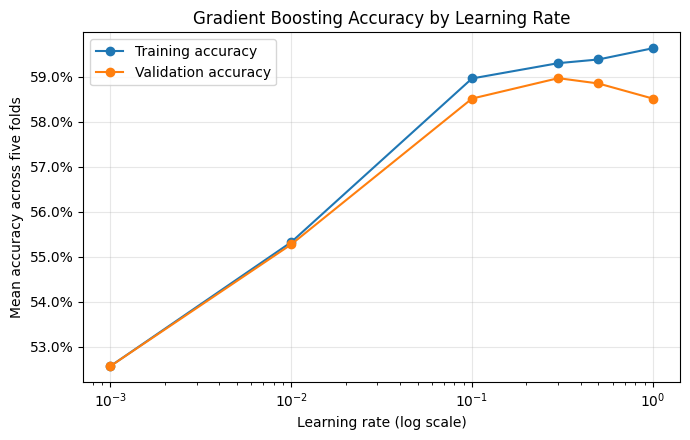

In [17]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

gb_results = pd.DataFrame(gb_search.cv_results_)
gb_results["learning_rate"] = gb_results["param_model__learning_rate"].astype(float)

gb_results = gb_results[
    (gb_results["param_model__n_estimators"] == gb_search.best_params_["model__n_estimators"]) &
    (gb_results["param_model__max_depth"] == gb_search.best_params_["model__max_depth"])
]

gb_results = gb_results.sort_values("learning_rate")

display(
    gb_results[["learning_rate", "mean_train_score",
                "mean_test_score", "std_test_score"]]
    .rename(columns={
        "learning_rate": "Learning rate",
        "mean_train_score": "Mean training accuracy",
        "mean_test_score": "Mean validation accuracy",
        "std_test_score": "Validation accuracy SD",
    })
    .round(4)
)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(gb_results["learning_rate"], gb_results["mean_train_score"],
        marker="o", label="Training accuracy")
ax.plot(gb_results["learning_rate"], gb_results["mean_test_score"],
        marker="o", label="Validation accuracy")
ax.set_xscale("log")
ax.set_xlabel("Learning rate (log scale)")
ax.set_ylabel("Mean accuracy across five folds")
ax.set_title("Gradient Boosting Accuracy by Learning Rate")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

With 100 trees and a maximum depth of 1, mean validation accuracy rose from 52.6% at a learning rate of 0.001 to a peak of 59.0% at 0.3. At higher rates, training accuracy kept rising while validation accuracy dipped slightly, which suggests mild overfitting. The four rates tested from 0.1 to 1.0 all scored within about half a percentage point of the peak.

## Model comparison

I compared Random Forest and Gradient Boosting using accuracy and ROC
AUC. Both models used the same five outer folds from the development
set. Within each outer fold, I tuned each model on the training portion
and scored it on the held-out portion. The table shows the mean and
standard deviation of each metric across the five outer folds.

In [18]:
from sklearn.model_selection import cross_validate

outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=43)

comparison = []
for model_name, search in [("Random Forest", rf_search),
                           ("Gradient Boosting", gb_search)]:
    scores = cross_validate(
        search, X, y,
        cv=outer_cv,
        scoring=["accuracy", "roc_auc"],
        n_jobs=1,   # the search inside already uses n_jobs=-1
    )
    comparison.append({
        "Model": model_name,
        "Mean accuracy": scores["test_accuracy"].mean(),
        "Accuracy SD": scores["test_accuracy"].std(),
        "Mean ROC AUC": scores["test_roc_auc"].mean(),
        "ROC AUC SD": scores["test_roc_auc"].std(),
    })

display(pd.DataFrame(comparison).set_index("Model").round(3))

,Mean accuracy,Accuracy SD,Mean ROC AUC,ROC AUC SD
Model,,,,
Random Forest,0.583,0.005,0.615,0.008
Gradient Boosting,0.588,0.008,0.617,0.008


Gradient Boosting had a mean accuracy of 58.8%, compared with 58.3% for Random Forest. Both models scored above the 52.6% baseline of always predicting no past-year counseling or therapy use. Their ROC AUC scores were also close, at 0.617 for Gradient Boosting and 0.615 for Random Forest. ROC AUC measures how well a model ranks students who reported using counseling or therapy above students who did not. A score of 0.5 means chance-level ranking, and 1.0 means perfect ranking. An AUC of about 0.62 suggests that both models had some ability to distinguish students who reported using counseling or therapy from those who did not. Gradient Boosting scored 0.5 percentage points higher in accuracy and 0.002 higher in ROC AUC, so the two models performed similarly overall. Both accuracy scores were slightly lower than the earlier tuning scores, which is consistent with evaluating each model on folds held out from tuning.

## Summary of work and main findings

I prepared the development data, handled missing demographic responses, and tuned Random Forest and Gradient Boosting to predict past-year counseling or therapy use. I compared both models using nested cross-validation on the development set. The selected Random Forest used 100 trees, a maximum depth of 5, and max_features="sqrt". The selected Gradient Boosting model used 100 trees, a maximum depth of 1, and a learning rate of 0.3.

Gradient Boosting had a mean accuracy of 58.8%, and Random Forest had 58.3%. Both had a ROC AUC of about 0.62. The models performed similarly, and the demographic and symptom severity variables helped only a little in distinguishing students who reported using counseling or therapy from those who did not. Both models scored above the 52.6% baseline of always predicting no past-year counseling or therapy use.

## Limitations
Both models had a ROC AUC of about 0.62, suggesting that they had limited ability to distinguish students who reported using counseling or therapy from those who did not. Several configurations scored within about half a percentage point of the best settings, and testing a wider range of hyperparameters might have led to different choices. The models used age, depression symptom severity, gender, and race or ethnicity. Other factors, such as access to care and attitudes toward treatment, may also matter. Counseling or therapy use was self-reported, and I evaluated both models within the development set. The reporting set is reserved for my group’s final evaluation. This analysis addresses how well the selected variables predict reported use. Questions about what causes students to seek care would require a different study design.